<h1 style="color:#041E42; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">
  <img src="https://upload.wikimedia.org/wikipedia/en/thumb/7/7a/University_of_Edinburgh_ceremonial_roundel.svg/360px-University_of_Edinburgh_ceremonial_roundel.svg.png" 
       style="vertical-align:middle; margin-right:10px; width:2em;" />
  The University of Edinburgh
</h1>

<h2 style="color:#005EB8; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">MSc Data Science for Health and Social Care </h2>

<div style="border-left:6px solid #005EB8; background:#F5F9FC; padding:0.8em; border-radius:6px; margin:1em 0;">
  <b>Module:</b> Foundations of Machine Learning  

  <b>Course Organiser:</b> Mr Christopher Aldous Oldnall  
</div>

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#FFF7E6;
  border-left:6px solid #F4A261;
  padding:1.3em 1.4em;
  border-radius:10px;
  margin-top:1.5em;
  margin-bottom:2em;
  max-width:900px;
">
  <h2 style="margin-top:0;">📱 Tutorial 4: Discovering Patterns in mHealth App Usage</h2>

  <p>
    In this tutorial, you will work with participant-level data collected from an mHealth
    application that records physiological signals and activity-related measurements.
    Instead of predicting a known outcome, your goal is to explore whether meaningful
    patterns emerge naturally within the data.
  </p>

  <p>
    The aim of this session is to understand how <strong>unsupervised learning</strong>
    methods can identify structure in complex health datasets. These approaches do not
    rely on labelled outcomes. Instead, they attempt to discover groups of participants
    who exhibit similar behavioural or physiological profiles.
  </p>

  <p>
    You will experiment with several clustering algorithms, including
    <strong>k-means clustering</strong>, <strong>hierarchical clustering</strong>,
    and <strong>DBSCAN</strong>. You will also explore dimensionality reduction
    techniques such as <strong>PCA</strong>, <strong>t-SNE</strong>, and
    <strong>UMAP</strong> to visualise the structure of the data in two dimensions.
  </p>

  <p>
    The tutorial follows a typical unsupervised learning workflow:
  </p>

  <ul>
    <li>Inspecting and preparing the dataset for analysis</li>
    <li>Applying clustering algorithms to identify potential activity patterns</li>
    <li>Visualising structure using dimensionality reduction</li>
    <li>Comparing clustering results using metrics such as silhouette score and adjusted Rand index</li>
    <li>Reflecting on how modelling choices influence the patterns we observe</li>
  </ul>

  <p>
    Throughout the notebook, you will encounter <strong>task blocks</strong> that prompt
    you to adjust clustering parameters, compare algorithms, and interpret visualisations
    of the participant data.
  </p>

  <p style="margin-bottom:0;">
    By the end of this tutorial, you should be able to explain how unsupervised learning
    methods can reveal hidden structure in behavioural and physiological datasets, and
    how dimensionality reduction can help interpret complex high-dimensional data.
  </p>
</div>

__Pair programming shared link__

Run the following cell without changing it. It only works on Noteable.

In [2]:
! printf "\n\nLink below can be send to someone to share your Noteable session:\n\nhttps://noteable.edina.ac.uk/user/$(jupyter notebook list | grep -oP '(?<=user\/).*(?=\/\?)' )/lab?token=$( jupyter notebook list | grep -oP '(?<=token=).*(?= ::)' )\n\n"



Link below can be send to someone to share your Noteable session:

https://noteable.edina.ac.uk/user/$(jupyter notebook list | grep -oP '(?<=user\/).*(?=\/\?)' )/lab?token=$( jupyter notebook list | grep -oP '(?<=token=).*(?= ::)' )



In [1]:
# Uncomment the below if you haven't already installed the packages 
# !pip install pandas numpy matplotlib seaborn scikit-learn umap-learn

In [2]:
# 📦 Standard package loading.
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.edgecolor": "#041E42",
    "axes.labelcolor": "#041E42",
    "xtick.color": "#041E42",
    "ytick.color": "#041E42",
    "text.color": "#041E42"
})

print("✅ Standard packages loaded and plotting style set to Edinburgh pallete")

✅ Standard packages loaded and plotting style set to Edinburgh pallete


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#E8F4FA;
  border-left:6px solid #2C7BE5;
  padding:1.2em 1.3em;
  border-radius:8px;
  margin-bottom:1.5em;
  max-width:900px;
">
<h3 style="margin-top:0;">📊 Task 1 — Exploring mHealth Behaviour</h3>

<p>
Before applying unsupervised learning, it is useful to explore how participants
use the mHealth application.
</p>

<p>
Investigate the distributions of:
</p>

<ul>
<li>mHealth app usage</li>
<li>medication adherence</li>
<li>hospital days</li>
<li>SF-36 quality-of-life score</li>
</ul>

<p>
Which variables appear most variable across participants?
Which ones might be most informative for identifying participant groups?
</p>
</div>

In [3]:
mhealth = pd.read_csv("../data/week4/syntheticISHSC_2025.csv")

In [4]:
mhealth.describe(include="all")

,participant_id,sex,age,condition,mHealth_app_usage,medication_adherence,hospital_days,sf36_score
count,8954.000000,8954,8954.000000,8954,8954,8954.000000,8954.000000,8954.000000
unique,NaN,2,NaN,3,4,NaN,NaN,NaN
top,NaN,M,NaN,Hypertension,Never,NaN,NaN,NaN
freq,NaN,4495,NaN,5509,3604,NaN,NaN,NaN
mean,4477.500000,NaN,59.986541,NaN,NaN,58.462484,1.930757,46.553843
std,2584.941489,NaN,12.012553,NaN,NaN,19.193349,2.378491,10.531046
min,1.000000,NaN,18.390118,NaN,NaN,24.016278,0.000000,12.837914
25%,2239.250000,NaN,51.949111,NaN,NaN,45.223900,0.000000,39.243673
50%,4477.500000,NaN,59.898021,NaN,NaN,51.842319,1.000000,46.021811
75%,6715.750000,NaN,68.311145,NaN,NaN,63.809103,3.000000,53.466854


<Axes: ylabel='mHealth_app_usage'>

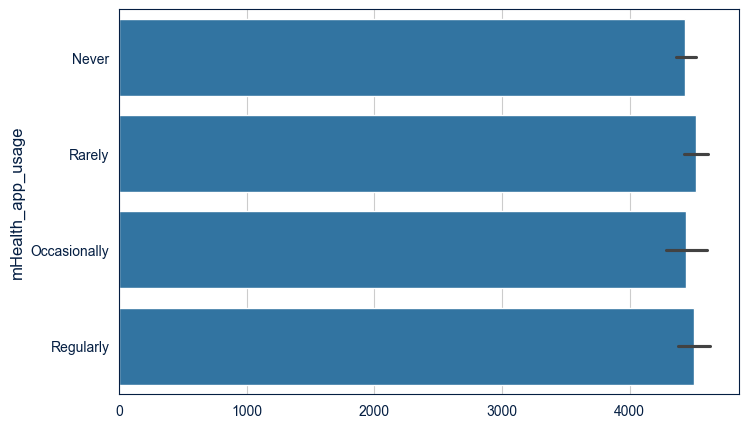

In [5]:
sns.barplot(mhealth['mHealth_app_usage'])

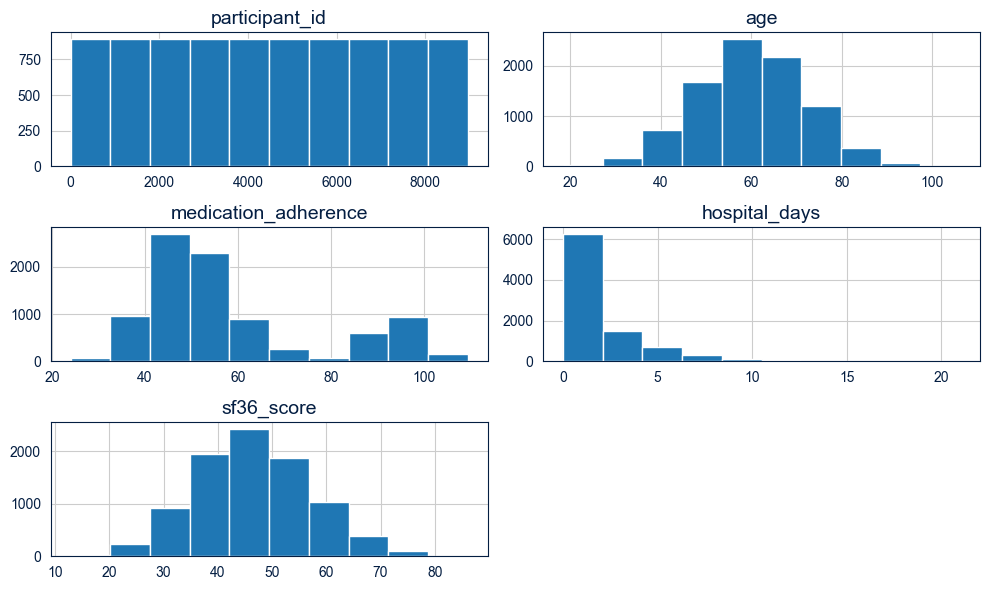

In [6]:
continuous_variables = ['medication_adherence', 'hospital_days', 'sf36_score']

mhealth[mhealth.columns].hist(figsize=(10,6))
plt.tight_layout()
plt.show()

`age`, `sf36_score` seem to be normally distrubted and the most variable. `medication_adherence` seems to be bimodal and so might form/push data points into other clusters. `participant_id` is irrelavant.

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#FFF3CD;
  border-left:6px solid #F4A261;
  padding:1.2em 1.3em;
  border-radius:8px;
  margin-bottom:1.5em;
  max-width:900px;
">
<h3 style="margin-top:0;">🔎 Task 2 — Visual Clues of Hidden Groups</h3>

<p>
Before running clustering algorithms, we can look for visual hints
of possible participant groups.
</p>

<p>
Create scatter plots comparing:
</p>

<ul>
<li>mHealth app usage vs medication adherence</li>
<li>mHealth app usage vs hospital days</li>
<li>mHealth app usage vs SF-36 score</li>
</ul>

<p>
Do you observe any natural groupings or trends?
</p>
</div>

<Axes: xlabel='mHealth_app_usage', ylabel='medication_adherence'>

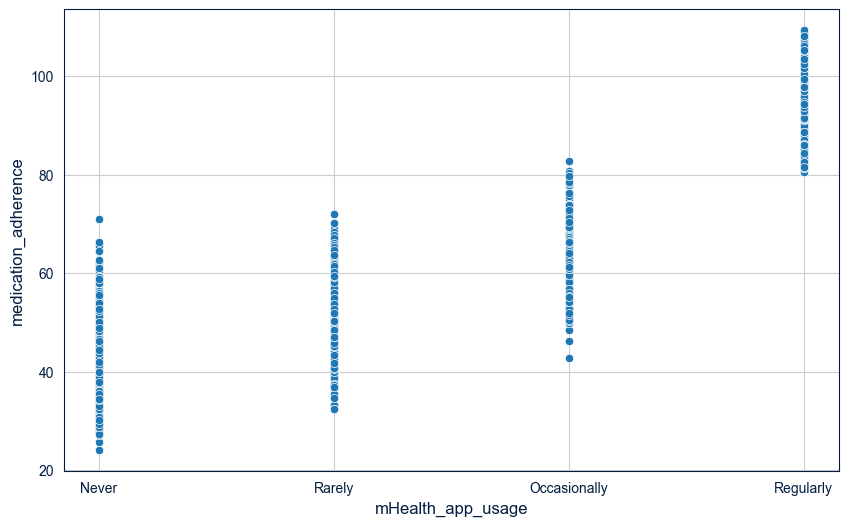

In [7]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='mHealth_app_usage', y='medication_adherence', data=mhealth)

<Axes: xlabel='mHealth_app_usage', ylabel='hospital_days'>

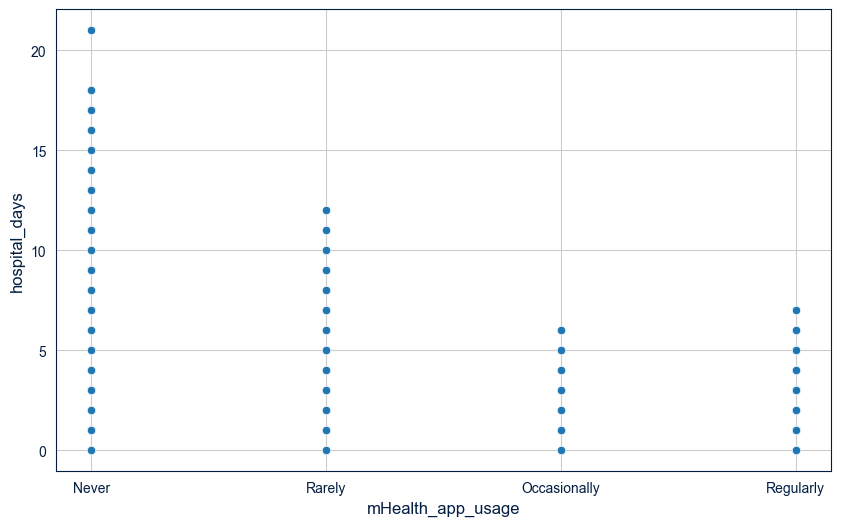

In [8]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='mHealth_app_usage', y='hospital_days', data=mhealth)

<Axes: xlabel='mHealth_app_usage', ylabel='sf36_score'>

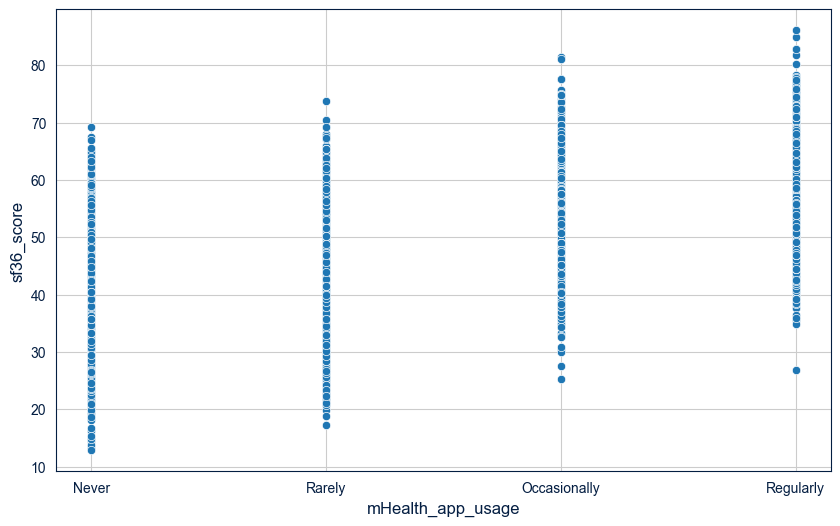

In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='mHealth_app_usage', y='sf36_score', data=mhealth)

The app seems to be keeping people to adhere to their medication, and as a consequence they are more happy and also have less hospital days.

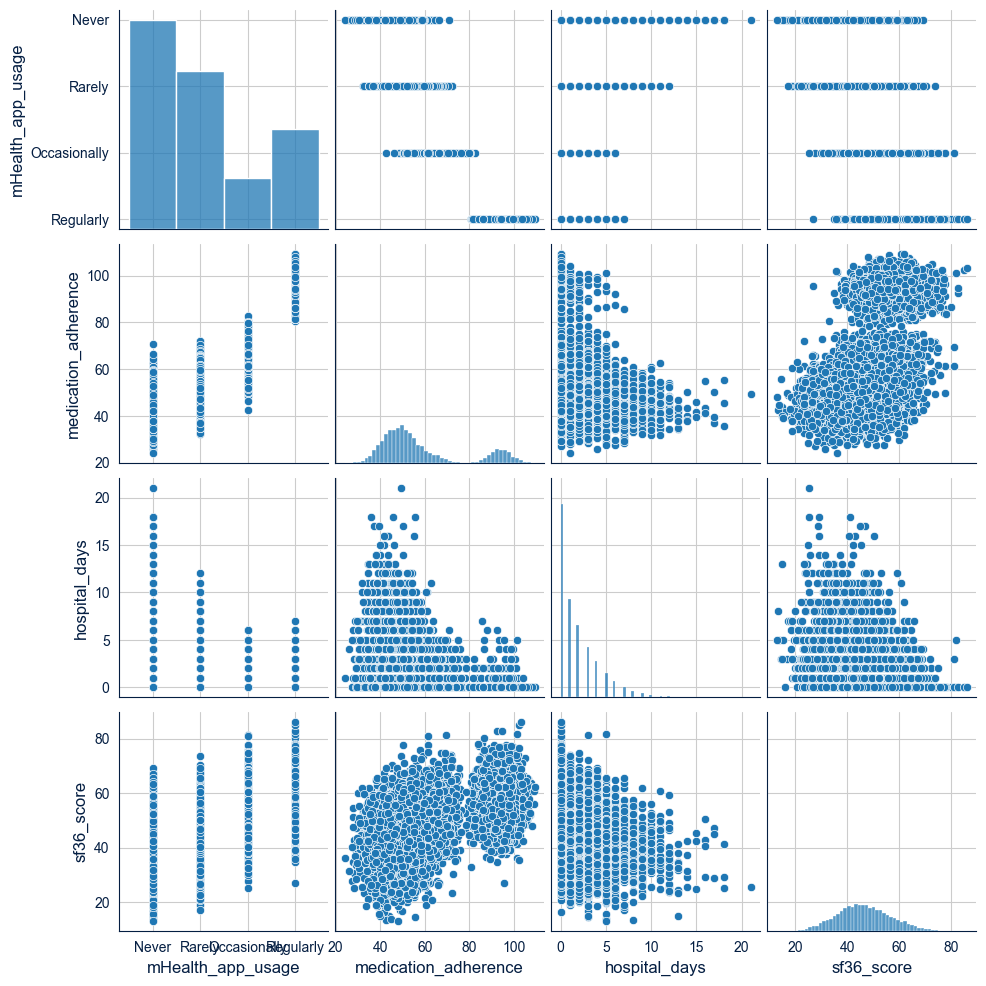

In [10]:
sns.pairplot(mhealth, vars=['mHealth_app_usage', 'medication_adherence', 'hospital_days', 'sf36_score'])

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#E9F7EF;
  border-left:6px solid #2A9D8F;
  padding:1.2em 1.3em;
  border-radius:8px;
  margin-bottom:1.5em;
  max-width:900px;
">
<h3 style="margin-top:0;">🧠 Task 3 — Clustering Health Behaviour Profiles</h3>

<p>
Suppose we want to identify different types of mHealth users.
</p>

<p>
Using the variables below, apply k-means clustering to see whether
participants naturally group into behavioural profiles:
</p>

<ul>
<li>mHealth app usage</li>
<li>medication adherence</li>
<li>hospital days</li>
<li>SF-36 score</li>
</ul>

<p>
How many clusters appear reasonable?
</p>
</div>

In [11]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder

mhealth.drop(columns=['participant_id'], inplace=True)

categorical_variables = ['sex', 'condition', 'mHealth_app_usage']
continuous_variables = ['age', 'medication_adherence', 'hospital_days', 'sf36_score']

mhealth = pd.get_dummies(mhealth, columns=categorical_variables, drop_first=True)
mhealth

,age,medication_adherence,hospital_days,sf36_score,sex_M,condition_Diabetes,condition_Hypertension,mHealth_app_usage_Occasionally,mHealth_app_usage_Rarely,mHealth_app_usage_Regularly
0,44.393436,38.520224,1,36.089403,True,False,True,False,False,False
1,55.148064,47.462577,0,28.132801,True,False,True,False,False,False
2,71.790781,51.138097,2,41.112643,True,False,True,False,False,False
3,63.951114,47.396799,3,41.822499,False,False,True,False,False,False
4,67.828167,48.618063,0,36.361832,True,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
8949,66.210125,66.322299,1,67.271922,True,False,True,True,False,False
8950,64.476781,41.995215,0,31.927972,False,False,True,False,False,False
8951,43.647331,61.248608,0,43.519663,True,True,False,True,False,False
8952,52.608383,103.586057,0,63.185549,True,True,False,False,False,True


In [12]:
scaler = StandardScaler()
mhealth[continuous_variables] = scaler.fit_transform(mhealth[continuous_variables])

In [13]:
mhealth

,age,medication_adherence,hospital_days,sf36_score,sex_M,condition_Diabetes,condition_Hypertension,mHealth_app_usage_Occasionally,mHealth_app_usage_Rarely,mHealth_app_usage_Regularly
0,-1.298140,-1.039077,-0.391344,-0.993731,True,False,True,False,False,False
1,-0.402808,-0.573142,-0.811803,-1.749311,True,False,True,False,False,False
2,0.982714,-0.381632,0.029114,-0.516711,True,False,True,False,False,False
3,0.330054,-0.576570,0.449572,-0.449301,False,False,True,False,False,False
4,0.652822,-0.512937,-0.811803,-0.967860,True,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
8949,0.518119,0.409530,-0.391344,1.967443,True,False,True,True,False,False
8950,0.373817,-0.858015,-0.811803,-1.388911,False,False,True,False,False,False
8951,-1.360254,0.145169,-0.811803,-0.288134,True,True,False,True,False,False
8952,-0.614238,2.351132,-0.811803,1.579390,True,True,False,False,False,True


In [14]:
mhealth_kmeans = KMeans(n_clusters=4, random_state=42)
mhealth_kmeans_labels = mhealth_kmeans.fit_predict(mhealth)

As there are four categories in the app usage variable, we choose to use four clusters here.

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

 <div style="
  background:#FDEDEC;
  border-left:6px solid #E63946;
  padding:1.2em 1.3em;
  border-radius:8px;
  margin-bottom:1.5em;
  max-width:900px;
">
<h3 style="margin-top:0;">🏥 Task 4 — Interpreting Clusters</h3>

<p>
Once clusters have been identified, we can investigate whether they
correspond to meaningful health patterns.
</p>

<p>
Calculate the average values of each variable within each cluster.
</p>

<p>
Do some clusters correspond to participants with higher hospital
utilisation or lower quality-of-life scores?
</p>
</div>

In [15]:
mhealth['cluster_number'] = mhealth_kmeans_labels
mhealth.groupby('cluster_number')[continuous_variables].mean()

,age,medication_adherence,hospital_days,sf36_score
cluster_number,,,,
0,-0.015825,-0.636101,1.786398,-0.784106
1,-0.024759,1.764950,-0.757973,1.095932
2,0.882539,-0.420473,-0.189320,-0.164217
3,-0.787174,-0.417558,-0.207980,-0.161294


Cluster 0 has higher hospital days, whilst cluster 3 has the lowest sf36_score. 

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#EEF2FF;
  border-left:6px solid #6C63FF;
  padding:1.2em 1.3em;
  border-radius:8px;
  margin-bottom:1.5em;
  max-width:900px;
">
<h3 style="margin-top:0;">📉 Task 5 — Visualising Clusters</h3>

<p>
High-dimensional data can be difficult to interpret.
</p>

<p>
Use Principal Component Analysis (PCA) to project the behavioural
variables into two dimensions and visualise the clusters.
</p>
</div>

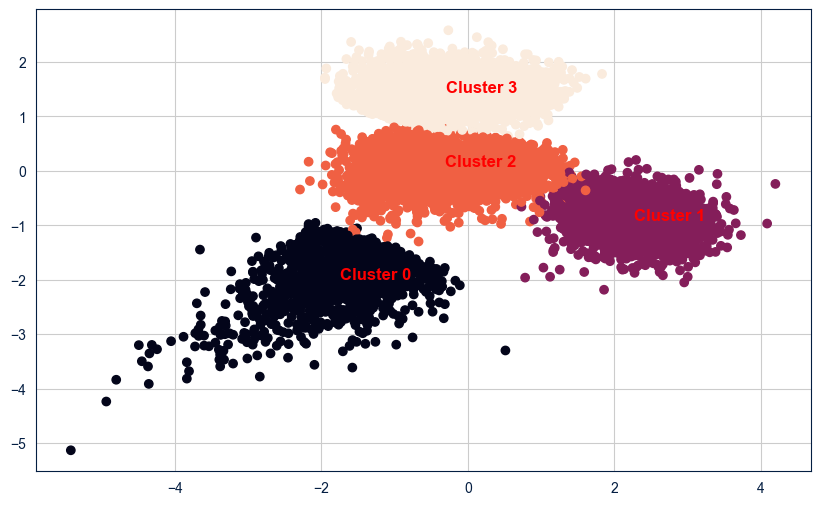

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
mhealth_pca = pca.fit_transform(mhealth)

plt.figure(figsize=(10, 6))
plt.scatter(mhealth_pca[:, 0], mhealth_pca[:, 1], c=mhealth_kmeans_labels)
# Add in cluster labels for clarity in a legend
for i in range(4):
    plt.text(np.mean(mhealth_pca[mhealth_kmeans_labels == i, 0]), 
             np.mean(mhealth_pca[mhealth_kmeans_labels == i, 1]), 
             f'Cluster {i}', 
             fontsize=12, 
             weight='bold',
             color='red')
plt.show()

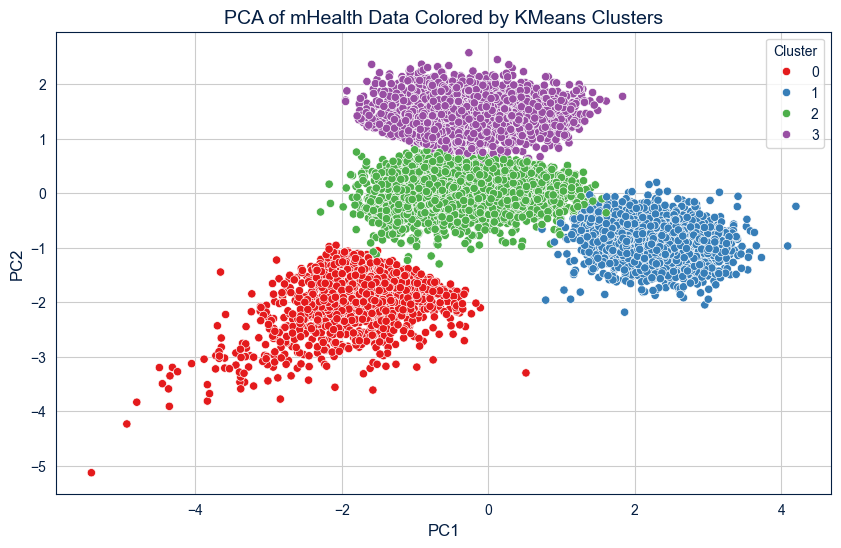

In [26]:
# alternatively transform into a pandas dataframe for easier plotting with seaborn
mhealth_pca_df = pd.DataFrame(mhealth_pca, columns=['PC1', 'PC2'])
mhealth_pca_df['cluster'] = mhealth_kmeans_labels

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='cluster', data=mhealth_pca_df, palette='Set1')
plt.title('PCA of mHealth Data Colored by KMeans Clusters')
plt.legend(title='Cluster')
plt.show()

The clusters seem to be fairly distinct.

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F0FFF4;
  border-left:6px solid #2ECC71;
  padding:1.2em 1.3em;
  border-radius:8px;
  margin-bottom:1.5em;
  max-width:900px;
">
<h3 style="margin-top:0;">🧩 Task 6 — Comparing Clusters with Known Conditions</h3>

<p>
Although clustering was performed without using the
<strong>condition</strong> variable, we can now check whether the
discovered clusters correspond to clinical groups.
</p>

<p>
Compare cluster membership with the condition variable.
</p>
</div>

In [28]:
pd.crosstab(mhealth['cluster_number'], mhealth['condition_Diabetes'])

condition_Diabetes,False,True
cluster_number,,
0,1079,342
1,1435,424
2,2025,691
3,2263,695


In [29]:
pd.crosstab(mhealth['cluster_number'], mhealth['condition_Hypertension'])

condition_Hypertension,False,True
cluster_number,,
0,528,893
1,705,1154
2,1119,1597
3,1093,1865


In [ ]:
pd.crosstab(mhealth['cluster_number'], mhealth['condition_Hypertension'])

INSERT YOUR MARKDOWN HERE